# Homework 4: Evaluation

This notebook works through the 2026 lead-scoring homework. It covers data preparation, ROC AUC, threshold-based metrics, and cross-validation for logistic regression.

The target is `converted`: whether a lead signed up for the platform.

In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,KFold
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

## 1. Load and inspect the data

Load the pinned 2026 lead-scoring dataset, then inspect a few rows and the feature types before preparing the data.

In [2]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/refs/heads/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## 2. Data preparation

Check each feature for missing values. Replace missing categorical values with `NA` and missing numerical values with `0.0`, as specified in the homework.

In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [6]:
cat_cols = ['lead_source','industry','employment_status','location']
for c in cat_cols:
    df[c] = df[c].fillna('NA')

In [7]:
num_cols = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
for c in num_cols:
    df[c] = df[c].fillna(0.0)

## 3. Train, validation, and test split

Create the required 60% training, 20% validation, and 20% test partitions using the homework's specified `random_state=1` splits. The target column is `converted`.

In [8]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [9]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

## 4. Question 1 — ROC AUC feature importance

Use each of the four numerical features as a score on the training set. If its ROC AUC is below 0.5, reverse its direction by negating the feature, then compare the AUC values.

In [10]:
for c in num_cols:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    print(f'{c}: {round(auc,3)}')    

#answer: lead_score

annual_income: 0.608
number_of_courses_viewed: 0.723
interaction_count: 0.765
lead_score: 0.788


## 5. Question 2 — Logistic regression and validation AUC

Convert the categorical and numerical features to model inputs with `DictVectorizer`, fit the requested logistic regression on the training partition, and evaluate its ROC AUC on the validation partition.

In [11]:
train_dicts = df_train[cat_cols + num_cols].to_dict(orient = 'records')
val_dicts = df_val[cat_cols + num_cols].to_dict(orient = 'records')

dv = DictVectorizer(sparse=False)
dv.fit(train_dicts)

X_train = dv.transform(train_dicts)
X_val = dv.transform(val_dicts)

In [12]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [13]:
y_pred = model.predict_proba(X_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
round(auc,3)

0.732

## 6. Question 3 — Precision and recall across thresholds

Use the validation probabilities to calculate precision and recall for thresholds from 0.00 to 1.00 in steps of 0.01. The plot helps identify where the two curves are closest; thresholds where both metrics are zero are not considered.

In [14]:
thresholds = np.linspace(0.0,1,101)
precisions = []
recalls = []
f1s = []
for t in thresholds:

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)

    tp = (predicted_positive & actual_positive).sum()
    fp = (predicted_positive & actual_negative).sum()
    fn = (predicted_negative & actual_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / ( tp + fn) if (tp + fp) > 0 else np.nan
    f1 = 2 * ((precision * recall) / (precision + recall))

    f1s.append(f1)
    precisions.append(precision)
    recalls.append(recall)

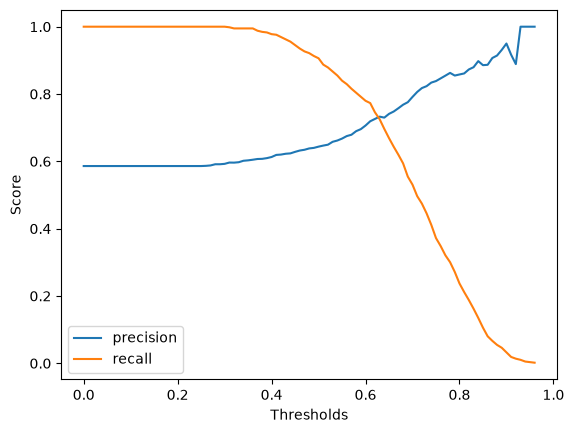

In [15]:
plt.plot(thresholds, precisions, label = 'precision')
plt.plot(thresholds, recalls, label = 'recall')
plt.xlabel('Thresholds')
plt.ylabel('Score')
plt.legend()
plt.show()

## 7. Question 4 — F1 score

Precision and recall trade off against one another. The F1 score combines them as \(F_1 = 2PR / (P + R)\), where `P` is precision and `R` is recall. Use the values calculated across thresholds to identify the threshold with the highest F1 score.

In [16]:
best_idx = np.nanargmax(f1s)
best_f1 = f1s[best_idx]
best_threshold = thresholds[best_idx]

print(f'Best F1 is: {round(best_f1,3)} at threshold = {round(best_threshold,3)}')

Best F1 is: 0.758 at threshold = 0.41


## 8. Questions 5–6 — Cross-validation and C tuning

Use shuffled 5-fold cross-validation on `df_full_train`, with `random_state=1`. For each fold, fit the vectorizer on that fold's training data, train logistic regression, and measure validation ROC AUC. The code compares the requested `C` values and reports the mean and standard deviation of the fold scores for each value.

In [32]:
C = [0.000001, 0.001, 1]
for c in tqdm(C):

    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    results = []

    for train_idx, val_idx in kfold.split(df_full_train):
        
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]
    
        y_fold_train = df_fold_train.converted.values
        y_fold_val = df_fold_val.converted.values
    
        train_folds_dicts = df_fold_train[cat_cols + num_cols].to_dict(orient = 'records')
        val_folds_dicts = df_fold_val[cat_cols + num_cols].to_dict(orient = 'records')
    
        dv_fold = DictVectorizer(sparse=False)
        dv_fold.fit(train_folds_dicts)
    
        X_fold_train = dv_fold.transform(train_folds_dicts)
        X_fold_val = dv_fold.transform(val_folds_dicts)
    
        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_fold_train, y_fold_train)
    
        y_scores = model.predict_proba(X_fold_val)[:,1]
        auc = roc_auc_score(y_fold_val, y_scores)
        results.append(auc)

    print(f'C = {c} | ROC AUC (mean) = {round(np.mean(results), 3)} | ROC AUC (std) = { round(np.std(results), 3) }')

  0%|          | 0/3 [00:00<?, ?it/s]

C = 1e-06 | ROC AUC (mean) = 0.617 | ROC AUC (std) = 0.019
C = 0.001 | ROC AUC (mean) = 0.749 | ROC AUC (std) = 0.01
C = 1 | ROC AUC (mean) = 0.732 | ROC AUC (std) = 0.007


**Reading the results:** The final cell reports the standard deviation for the last candidate (`C = 1`), which answers Question 5. For Question 6, compare the printed mean AUC values: the displayed results are highest for `C = 0.001` (0.749).